In [1]:
import pandas as pd
import numpy as np
import torch
from torch import nn
from torchmetrics import Accuracy
from torch import optim
from torch.utils.data import DataLoader, TensorDataset,Dataset
from dotenv import load_dotenv
from datetime import datetime, timedelta
import os
import requests
load_dotenv()

True

In [2]:
import requests
import pandas as pd
 
BASE = "https://data-api.binance.vision/api/v3"
 
# ─────────────────────────────────────────────
# 1) KLINES — 90 days of hourly OHLCV (the time series)
# ─────────────────────────────────────────────
end_ms = int(pd.Timestamp.now(tz="UTC").timestamp() * 1000)
start_ms = end_ms - 90 * 24 * 3600 * 1000
 
columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "num_trades",
    "taker_buy_base", "taker_buy_quote", "ignore"
]
 
rows = []
while start_ms < end_ms:
    params = {"symbol": "BTCUSDT", "interval": "1h",
              "startTime": start_ms, "endTime": end_ms, "limit": 1000}
    data = requests.get(f"{BASE}/klines", params=params).json()
    if not isinstance(data, list) or not data:
        break
    rows.extend(data)
    start_ms = data[-1][0] + 1
 
df = pd.DataFrame(rows, columns=columns)
df["open_time"] = pd.to_datetime(df["open_time"], unit="ms")
df["close_time"] = pd.to_datetime(df["close_time"], unit="ms")
for col in ["open", "high", "low", "close", "volume", "quote_volume"]:
    df[col] = df[col].astype(float)
df["num_trades"] = df["num_trades"].astype(int)
df = df[["open_time", "open", "high", "low", "close", "volume", "num_trades"]]
 
# ─────────────────────────────────────────────
# 2) DEPTH — a snapshot of the order book RIGHT NOW
# ─────────────────────────────────────────────
depth = requests.get(f"{BASE}/depth",
                     params={"symbol": "BTCUSDT", "limit": 100}).json()
depth_df = pd.DataFrame({
    "bid_price":   [float(b[0]) for b in depth["bids"]],
    "bid_qty":     [float(b[1]) for b in depth["bids"]],
    "ask_price":   [float(a[0]) for a in depth["asks"]],
    "ask_qty":     [float(a[1]) for a in depth["asks"]],
    "last_update_id": depth["lastUpdateId"],
})
 
# ─────────────────────────────────────────────
# 3) AGGTRADES — recent aggregated trades (last ~1000)
# ─────────────────────────────────────────────
trades = requests.get(f"{BASE}/aggTrades",
                      params={"symbol": "BTCUSDT", "limit": 1000}).json()
trades_df = pd.DataFrame(trades)
trades_df["T"] = pd.to_datetime(trades_df["T"], unit="ms")
trades_df["p"] = trades_df["p"].astype(float)
trades_df["q"] = trades_df["q"].astype(float)
 
# ─────────────────────────────────────────────
# 4) EXCHANGEINFO — static metadata for BTCUSDT
# ─────────────────────────────────────────────
info = requests.get(f"{BASE}/exchangeInfo").json()
btc = [s for s in info["symbols"] if s["symbol"] == "BTCUSDT"][0]

df

,open_time,open,high,low,close,volume,num_trades
0,2026-05-10 16:00:00,81418.01,81500.00,81200.00,81378.25,595.22707,86414
1,2026-05-10 17:00:00,81378.25,81583.11,81220.00,81476.18,599.74468,90133
2,2026-05-10 18:00:00,81476.18,81493.11,81231.14,81271.96,268.90805,52194
3,2026-05-10 19:00:00,81271.96,81481.92,81148.00,81437.83,334.34752,55929
4,2026-05-10 20:00:00,81437.83,81459.66,80279.77,80734.88,1021.73969,188726
...,...,...,...,...,...,...,...
2155,2026-08-08 11:00:00,65005.88,65024.10,64957.00,64967.35,178.16146,19311
2156,2026-08-08 12:00:00,64967.36,65050.55,64924.00,65008.34,234.45077,31056
2157,2026-08-08 13:00:00,65008.33,65018.00,65000.00,65015.27,187.85749,16805
2158,2026-08-08 14:00:00,65015.27,65192.54,65015.27,65129.02,356.35929,44901


In [3]:
import numpy as np
 
df["log_return"] = np.log(df["close"] / df["close"].shift(1))
 
df["log_return_lag1"] = df["log_return"].shift(1)
df["log_return_lag2"] = df["log_return"].shift(2)
 
df["volatility_6"] = df["log_return"].rolling(6).std()
 
df["volume_change"] = df["volume"].pct_change()
df["ema_12"] = df["close"].ewm(span=12, adjust=False).mean()
df["ema_distance"] = df["close"] - df["ema_12"]

period = 14
 
delta = df["close"].diff()          # price change per bar
gain = delta.clip(lower=0)          # only up moves
loss = -delta.clip(upper=0)         # only down moves (as positive numbers)
 
avg_gain = gain.ewm(alpha=1/period, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/period, adjust=False).mean()
 
rs = avg_gain / avg_loss
df["rsi_14"] = 100 - (100 / (1 + rs))
ema_26 = df["close"].ewm(span=26, adjust=False).mean()
 
df["macd"] = df["ema_12"] - ema_26                 # the MACD line: fast EMA minus slow EMA
df["macd_signal"] = df["macd"].ewm(span=9, adjust=False).mean()  # smoothed MACD
df["macd_hist"] = df["macd"] - df["macd_signal"] 
df["sma_ret_20"] = df["log_return"].rolling(20).mean()  # histogram: gap between them
df = df.dropna().reset_index(drop=True)
df.columns

Index(['open_time', 'open', 'high', 'low', 'close', 'volume', 'num_trades',
       'log_return', 'log_return_lag1', 'log_return_lag2', 'volatility_6',
       'volume_change', 'ema_12', 'ema_distance', 'rsi_14', 'macd',
       'macd_signal', 'macd_hist', 'sma_ret_20'],
      dtype='str')

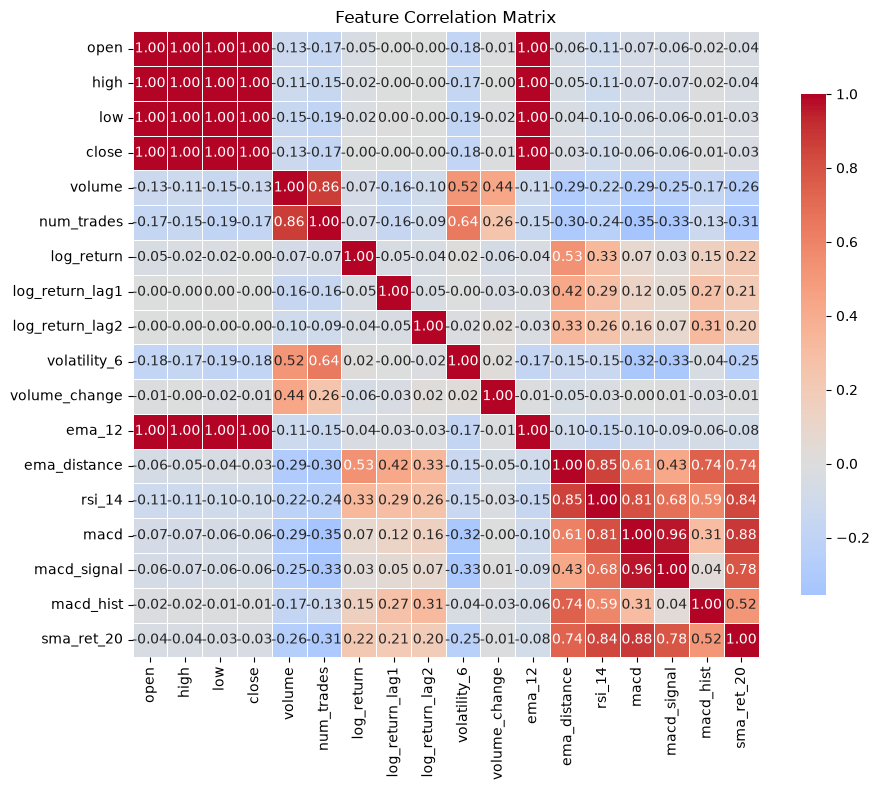

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix (only numeric columns, drop timestamp)
corr = df.drop(columns=['open_time']).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [5]:
# ── what the model will predict ───────────────────────────────
feature_cols = ["open", "high", "log_return",
                "log_return_lag2", "log_return_lag1",
                "volatility_6", "volume_change",
                "low", "close", "num_trades",'ema_distance','ema_12','rsi_14','macd_signal','macd_hist','sma_ret_20','macd']

 
TARGET = "close"                       # change this ONE name to retarget
target_idx = feature_cols.index(TARGET)     # computed, not memorized
 
print(f"Predicting the NEXT step's: {TARGET}  (column index {target_idx})")
print(dict(enumerate(feature_cols)))        # sanity check
 
values = df[feature_cols].to_numpy(dtype=np.float32)
 
# ── split ─────────────────────────────────────────────────────
train_end = int(len(values) * 0.7)
val_end   = int(len(values) * 0.85)
 
train = values[:train_end]
val   = values[train_end:val_end]
test  = values[val_end:]
 
mean = train.mean(axis=0)          # all 10 columns, including target
std  = train.std(axis=0)
std[std == 0] = 1.0
 
train = (train - mean) / std
val   = (val   - mean) / std
test  = (test  - mean) / std
 
# ── windows: X = 30 past steps, y = the step right after ──────
def windows(data, seq_len=30):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i:i + seq_len])
        y.append(data[i + seq_len, target_idx])   # named, explicit
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)
 
X_train, y_train = windows(train)
X_val, y_val = windows(val)
X_test, y_test = windows(test)
 
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("z-scored target sample:", y_train[:5])   # z-scored log returns, e.g. ±1.0

Predicting the NEXT step's: close  (column index 8)
{0: 'open', 1: 'high', 2: 'log_return', 3: 'log_return_lag2', 4: 'log_return_lag1', 5: 'volatility_6', 6: 'volume_change', 7: 'low', 8: 'close', 9: 'num_trades', 10: 'ema_distance', 11: 'ema_12', 12: 'rsi_14', 13: 'macd_signal', 14: 'macd_hist', 15: 'sma_ret_20', 16: 'macd'}
X_train: (1468, 30, 17)  y_train: (1468,)
z-scored target sample: [1.8450246 1.8671709 1.8475522 1.8319695 1.8417939]


In [6]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)

train_data_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_data_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_data_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [7]:
class Model(nn.Module):
    def __init__(self, input_size,hidden_size,num_stacked_layers,batch_first=True):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_stacked_layers = num_stacked_layers
        self.lstm = nn.LSTM(self.input_size,hidden_size,self.num_stacked_layers,batch_first=batch_first)
        #self.attention = nn.Linear(hidden_size,1)
        self.final = nn.Linear(hidden_size,1)


    def forward(self,x):
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_stacked_layers,batch_size,self.hidden_size)
        c0 = torch.zeros(self.num_stacked_layers,batch_size,self.hidden_size)
        out, _ = self.lstm(x,(h0,c0))

        #attention_scores = self.attention(out)  # (batch_size, seq_len, 1)
        #attention_weights = torch.softmax(attention_scores, dim=1)
        
        # Compute context vector (weighted sum)
        #context = torch.sum(attention_weights * out, dim=1)
        out = self.final(out[:,-1,:])
        return out


In [8]:
def train_model(model, train_loader, val_loader, optimizer, criterion, epoch, num_epochs,training_loss,testing_loss):
    model.train()
    train_loss = 0.0

    for feature, label in train_loader:
        optimizer.zero_grad()
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    training_loss.append(avg_train_loss)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for feature, label in val_loader:
            pred = model(feature).squeeze(-1)
            loss = criterion(pred, label)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    testing_loss.append(avg_val_loss)

    print(f"Epoch {epoch + 1}/{num_epochs} - train_loss: {avg_train_loss:.6f} - val_loss: {avg_val_loss:.6f}")

In [9]:
model = Model(X_train.shape[-1], hidden_size=5, num_stacked_layers=1)
model

Model(
  (lstm): LSTM(17, 5, batch_first=True)
  (final): Linear(in_features=5, out_features=1, bias=True)
)

Epoch 1/100 - train_loss: 0.363712 - val_loss: 0.048137
Epoch 2/100 - train_loss: 0.050353 - val_loss: 0.021027
Epoch 3/100 - train_loss: 0.029793 - val_loss: 0.009148
Epoch 4/100 - train_loss: 0.015104 - val_loss: 0.004565
Epoch 5/100 - train_loss: 0.007260 - val_loss: 0.002668
Epoch 6/100 - train_loss: 0.004688 - val_loss: 0.002218
Epoch 7/100 - train_loss: 0.003910 - val_loss: 0.002700
Epoch 8/100 - train_loss: 0.003589 - val_loss: 0.001866
Epoch 9/100 - train_loss: 0.003338 - val_loss: 0.001818
Epoch 10/100 - train_loss: 0.003015 - val_loss: 0.001476
Epoch 11/100 - train_loss: 0.002947 - val_loss: 0.001934
Epoch 12/100 - train_loss: 0.003113 - val_loss: 0.001765
Epoch 13/100 - train_loss: 0.002742 - val_loss: 0.001702
Epoch 14/100 - train_loss: 0.002789 - val_loss: 0.001336
Epoch 15/100 - train_loss: 0.002871 - val_loss: 0.001307
Epoch 16/100 - train_loss: 0.002460 - val_loss: 0.001387
Epoch 17/100 - train_loss: 0.002550 - val_loss: 0.001778
Epoch 18/100 - train_loss: 0.002724 - va

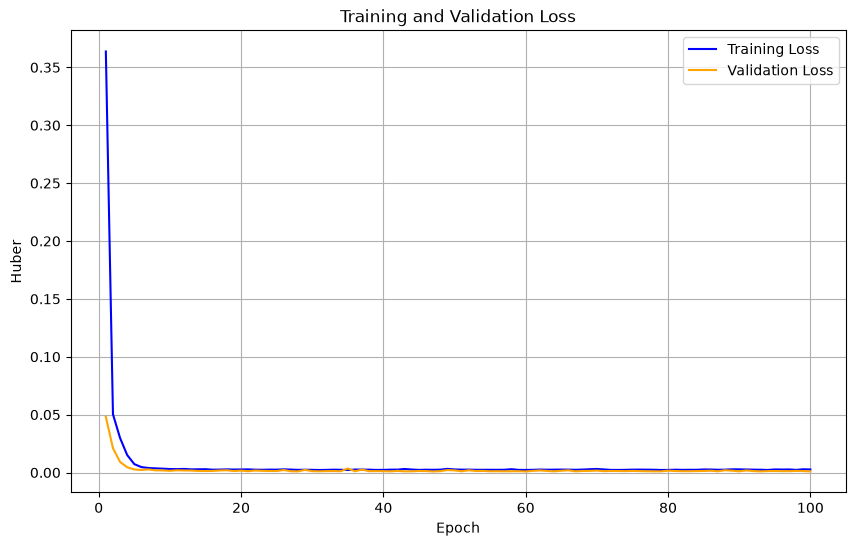

In [10]:
import matplotlib.pyplot as plt

learning_rate = 0.01
num_epochs = 100
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)

training_loss = []
testing_loss = []

for epoch in range(num_epochs):
    train_model(
        model,
        train_data_loader,
        val_data_loader,
        optimizer,
        criterion,
        epoch,
        num_epochs,
        training_loss,
        testing_loss
    )

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(training_loss) + 1), training_loss, label="Training Loss", color="blue")
plt.plot(range(1, len(testing_loss) + 1), testing_loss, label="Validation Loss", color="orange")
plt.xlabel("Epoch")
plt.ylabel("Huber")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
model.eval()

test_loss = 0.0
with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        test_loss += loss.item()

avg_test_loss = test_loss / len(test_data_loader)
print(f"Test loss: {avg_test_loss:.6f}")

Test loss: 0.000799


In [12]:

 
# --- 1. Gather ALL model predictions + targets on the test set ---
model.eval()
preds, actuals = [], []
with torch.no_grad():
    for feature, label in test_data_loader:
        preds.append(model(feature).squeeze(-1))
        actuals.append(label)
preds = torch.cat(preds)
actuals = torch.cat(actuals)
 
# --- 2. Mean baseline: predict the mean of TRAINING log returns ---
#    y_train is already z-scored, so this is ~0 (predicting "no change").
#    Using the train mean (not the test mean) avoids leakage.
baseline_value = y_train.mean()
baseline_preds = torch.full_like(actuals, float(baseline_value))
 
# --- 3. Evaluate both with identical metrics ---
def report(pred, target, name):
    mse  = ((pred - target) ** 2).mean()
    mae  = (pred - target).abs().mean()
    huber = nn.HuberLoss()(pred, target)
    print(f"{name:>14} | Huber: {huber:.6f} | RMSE: {mse.sqrt():.6f} | MAE: {mae:.6f}")
 
print("NORMALIZED space (what your test loss is reported in):")
report(preds, actuals, "LSTM")
report(baseline_preds, actuals, "Mean baseline")
 
# --- 4. Undo the z-score so numbers are real log returns ---
logret_mean, logret_std = mean[target_idx], std[target_idx]
 
pred_lr   = preds   * logret_std + logret_mean
base_lr   = baseline_preds * logret_std + logret_mean
actual_lr = actuals * logret_std + logret_mean
 
print("\nREAL log-return space (0.01 ≈ a 1% move):")
report(pred_lr, actual_lr, "LSTM")
report(base_lr, actual_lr, "Mean baseline")
 
print(f"\nBaseline predicts: {float(baseline_value):.4f} (normalized)")
print(f"                 = {float(base_lr[0]):.6f} log return ≈ {np.exp(float(base_lr[0])) - 1:.2%} per step")

NORMALIZED space (what your test loss is reported in):
          LSTM | Huber: 0.000432 | RMSE: 0.029381 | MAE: 0.020906
 Mean baseline | Huber: 0.125996 | RMSE: 0.501989 | MAE: 0.491692

REAL log-return space (0.01 ≈ a 1% move):
          LSTM | Huber: 146.318054 | RMSE: 206.329361 | MAE: 146.814682
 Mean baseline | Huber: 3452.421875 | RMSE: 3525.235352 | MAE: 3452.921875

Baseline predicts: -0.0391 (normalized)
                 = 67448.054688 log return ≈ inf% per step


C:\Users\somay\AppData\Local\Temp\ipykernel_21208\1259924835.py:40: RuntimeWarning: overflow encountered in exp
  print(f"                 = {float(base_lr[0]):.6f} log return ≈ {np.exp(float(base_lr[0])) - 1:.2%} per step")


In [13]:
#M

In [14]:
'''
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "learning_rate": learning_rate,
    "num_epochs": num_epochs,
    "mean": mean,
    "std": std,
    "price_mean": price_mean,
    "price_std": price_std,
    "training_loss": training_loss,
    "testing_loss": testing_loss,
    "rmse_usd": rmse,
    "mae_usd": mae
}, "bitcoin_lstm_model.pt")

'''

'\ntorch.save({\n    "model_state_dict": model.state_dict(),\n    "optimizer_state_dict": optimizer.state_dict(),\n    "learning_rate": learning_rate,\n    "num_epochs": num_epochs,\n    "mean": mean,\n    "std": std,\n    "price_mean": price_mean,\n    "price_std": price_std,\n    "training_loss": training_loss,\n    "testing_loss": testing_loss,\n    "rmse_usd": rmse,\n    "mae_usd": mae\n}, "bitcoin_lstm_model.pt")\n\n'

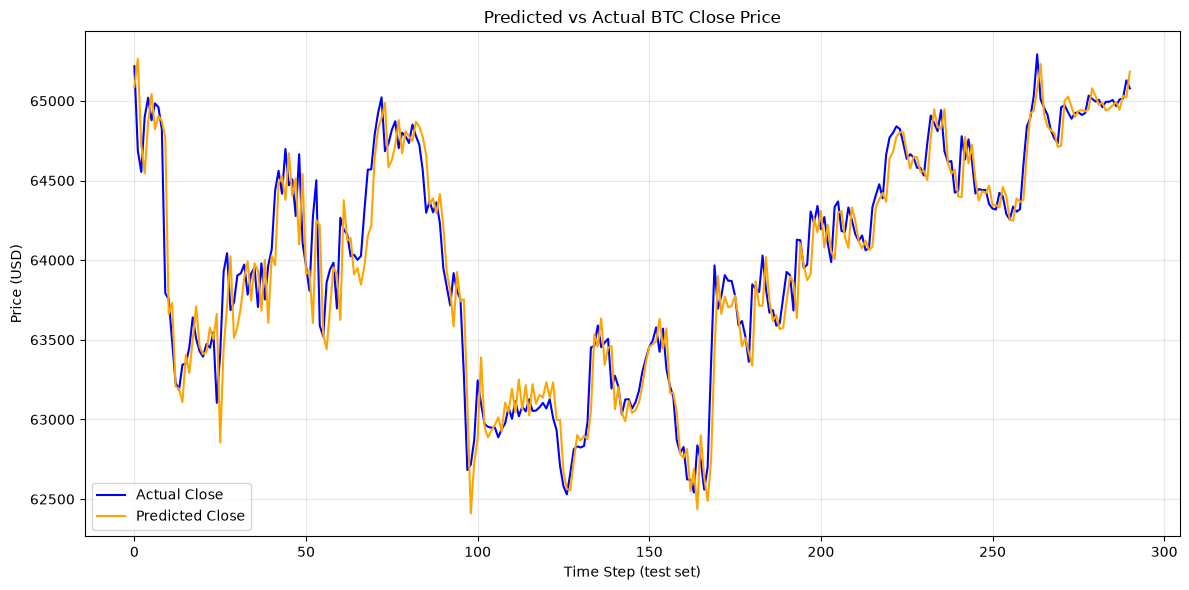

In [15]:
import matplotlib.pyplot as plt

# Un-z-score to real close prices (mean/std from training set only)
close_mean = mean[target_idx]
close_std  = std[target_idx]

pred_close   = preds   * close_std + close_mean
actual_close = actuals * close_std + close_mean

plt.figure(figsize=(12, 6))
plt.plot(actual_close.numpy(), label="Actual Close", color="blue", linewidth=1.5)
plt.plot(pred_close.numpy(), label="Predicted Close", color="orange", linewidth=1.5)
plt.xlabel("Time Step (test set)")
plt.ylabel("Price (USD)")
plt.title("Predicted vs Actual BTC Close Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:
model.eval()
 
# IMPORTANT fix: un-scale with the SAME mean/std the model was trained with
# (the `mean`/`std` arrays from your data-prep cell; index 0 = price column).
# Using df_combined-wide stats biases the USD values by a couple hundred dollars.
price_mean = mean[0]
price_std  = std[0]
 
all_preds = []
all_true = []
all_prev = []   # NEW: the last price the model saw before predicting
 
test_loss = 0.0  # NEW: normalized test loss, computed here so no NameError
 
with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        test_loss += criterion(pred, label).item()
 
        # convert from normalized space back to real price space
        pred_price = pred.cpu().numpy() * price_std + price_mean
        true_price = label.cpu().numpy() * price_std + price_mean
 
        # NEW: "previous price" = last step of the window, price is column 0
        prev_price = feature[:, -1, 0].cpu().numpy() * price_std + price_mean
 
        all_preds.append(pred_price)
        all_true.append(true_price)
        all_prev.append(prev_price)
 
all_preds = np.concatenate(all_preds)
all_true  = np.concatenate(all_true)
all_prev  = np.concatenate(all_prev)
 
# Real dollar-scale metrics
rmse = np.sqrt(np.mean((all_preds - all_true) ** 2))
mae  = np.mean(np.abs(all_preds - all_true))
 
# NEW: the hypothesis test — how good is "just copy the previous close"?
copy_rmse  = np.sqrt(np.mean((all_prev - all_true) ** 2))
copy_mae   = np.mean(np.abs(all_prev - all_true))
beats_copy = np.mean(np.abs(all_preds - all_true) < np.abs(all_prev - all_true))
 
print(f"Test MSE (normalized): {test_loss / len(test_data_loader):.6f}")
print(f"Test RMSE (USD): ${rmse:,.2f} | MAE (USD): ${mae:,.2f}")
print(f"Baseline (copy previous close): RMSE ${copy_rmse:,.2f} | MAE ${copy_mae:,.2f}")
print(f"Model beats 'copy previous close' on {beats_copy * 100:.1f}% of test windows")
 
# The table: Prev = last close the model saw | Pred = its guess | Actual = what happened
print("\n  Prev (last seen) |  Predicted   |   Actual")
for p, t, prev in zip(all_preds[:8], all_true[:8], all_prev[:8]):
    print(f"  ${prev:,.2f}   | ${p:,.2f} | ${t:,.2f}")

Test MSE (normalized): 0.000799
Test RMSE (USD): $206.56 | MAE (USD): $146.98
Baseline (copy previous close): RMSE $275.77 | MAE $191.33
Model beats 'copy previous close' on 56.7% of test windows

  Prev (last seen) |  Predicted   |   Actual
  $65,100.79   | $65,097.65 | $65,226.08
  $65,086.00   | $65,272.29 | $64,695.56
  $65,217.38   | $64,734.68 | $64,561.97
  $64,687.45   | $64,552.45 | $64,906.87
  $64,554.00   | $64,872.35 | $65,028.29
  $64,898.53   | $65,052.02 | $64,886.32
  $65,019.81   | $64,829.77 | $64,992.44
  $64,878.00   | $64,914.23 | $64,969.06


said UP,    was UP:   0
said UP,    was DOWN: 0
said DOWN,  was UP:   0
said DOWN,  was DOWN: 291
precision of UP calls: nan%   <-- 'when I said up, how often was I right'
base rate (hours that were actually up): 0.0%
overall accuracy: 100.0%


C:\Users\somay\AppData\Local\Temp\ipykernel_21208\917369647.py:21: RuntimeWarning: invalid value encountered in scalar divide
  print(f"precision of UP calls: {tp/(tp+fp):.1%}   <-- 'when I said up, how often was I right'")


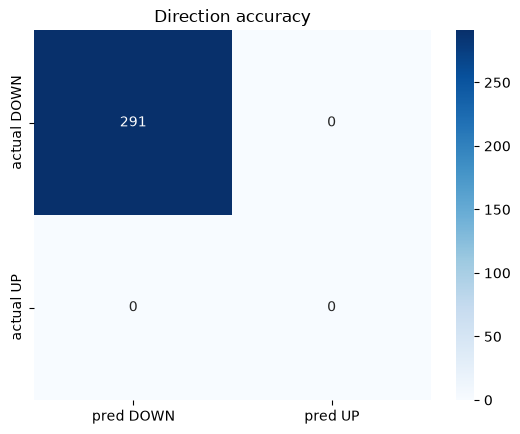

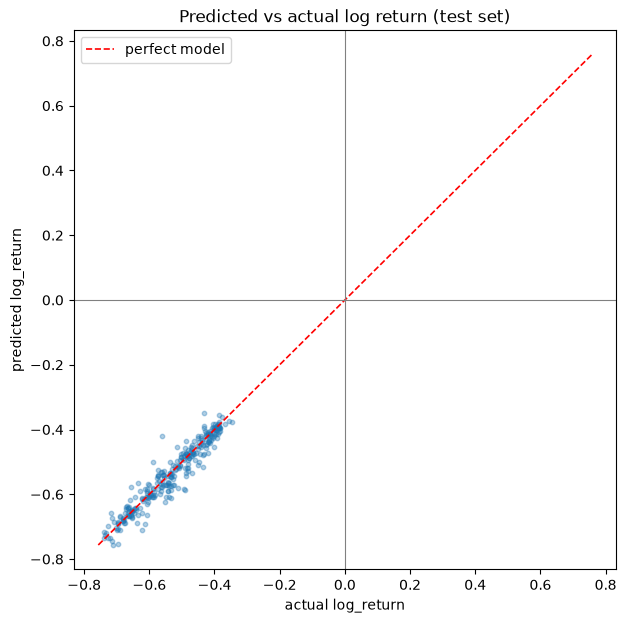

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 
preds = np.asarray(preds)      # your predicted log returns
actuals = np.asarray(actuals)  # your actual log returns
 
pred_up = preds > 0
actual_up = actuals > 0
 
# ── your question, as numbers ──
tp = (pred_up & actual_up).sum()     # said UP   -> was UP
fp = (pred_up & ~actual_up).sum()    # said UP   -> was DOWN
fn = (~pred_up & actual_up).sum()    # said DOWN -> was UP
tn = (~pred_up & ~actual_up).sum()   # said DOWN -> was DOWN
 
print(f"said UP,    was UP:   {tp}")
print(f"said UP,    was DOWN: {fp}")
print(f"said DOWN,  was UP:   {fn}")
print(f"said DOWN,  was DOWN: {tn}")
print(f"precision of UP calls: {tp/(tp+fp):.1%}   <-- 'when I said up, how often was I right'")
print(f"base rate (hours that were actually up): {(actuals > 0).mean():.1%}")
print(f"overall accuracy: {(tp+tn)/len(preds):.1%}")
 
# ── your question, as a picture: confusion matrix ──
cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["pred DOWN", "pred UP"],
            yticklabels=["actual DOWN", "actual UP"])
plt.title("Direction accuracy")
plt.show()
 
# ── the big picture: predicted vs actual ──
plt.figure(figsize=(7, 7))
plt.scatter(actuals, preds, alpha=0.35, s=10)
lim = max(abs(actuals.min()), abs(actuals.max()),
          abs(preds.min()), abs(preds.max()))
plt.plot([-lim, lim], [-lim, lim], "r--", lw=1.2, label="perfect model")
plt.axhline(0, color="gray", lw=0.8)
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("actual log_return")
plt.ylabel("predicted log_return")
plt.legend()
plt.title("Predicted vs actual log return (test set)")
plt.show()

In [17]:
import matplotlib.pyplot as plt

# Un-z-score to real close prices
close_mean = float(mean[target_idx])
close_std  = float(std[target_idx])

# LSTM predictions → real prices
pred_close   = (preds   * close_std + close_mean).numpy()
actual_close = (actuals * close_std + close_mean).numpy()

# Naive forecast: "next price = last price in the window" (persistence)
naive_z = X_test[:, -1, target_idx]             # last timestep's close (z-scored)
naive_close = naive_z * close_std + close_mean   # un-z-scored

# --- Metrics ---
def metrics(pred, actual, name):
    rmse = np.sqrt(((pred - actual) ** 2).mean())
    mae  = np.abs(pred - actual).mean()
    mape = (np.abs(pred - actual) / np.abs(actual)).mean() * 100
    print(f"{name:>14} | RMSE: ${rmse:,.2f} | MAE: ${mae:,.2f} | MAPE: {mape:.2f}%")

print("Real close-price space:")
metrics(pred_close, actual_close, "LSTM")
metrics(naive_close, actual_close, "Naive forecast")

# --- Plot ---
plt.figure(figsize=(14, 6))
plt.plot(actual_close, label="Actual Close", color="blue", linewidth=1.5)
plt.plot(pred_close, label="LSTM Predicted", color="orange", linewidth=1.5)
plt.plot(naive_close, label="Naive Forecast", color="green", linewidth=1.5, linestyle="--")
plt.xlabel("Time Step (test set)")
plt.ylabel("Price (USD)")
plt.title("LSTM vs Naive Forecast vs Actual — BTC Close Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


AttributeError: 'numpy.ndarray' object has no attribute 'numpy'